# RoadScan — resolution audit, no retraining

Compare the two saved YOLO26s checkpoints at 640, 768 and 960 on the fixed development domains using the small input package prepared in notebook 07. Test images and annotations are never loaded. Choose by worst-domain development mAP50–95, then mean. This is additional development tuning, not new independent evidence. No 92% result is promised.

## 1. Environment

Keep the same Ultralytics release and use the existing Kaggle PyTorch installation. No training API is called.

In [1]:
import sys
import subprocess
from pathlib import Path
print('Stage 1: installing the pinned evaluation dependency', flush=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '--retries', '2',
                '--timeout', '30', 'ultralytics==8.4.177'], check=True, timeout=180)
import json, shutil, gc, hashlib, time
from concurrent.futures import ThreadPoolExecutor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import yaml
from PIL import Image
from IPython.display import display
from ultralytics import YOLO
OUT = Path('/kaggle/working/resolution_audit')
OUT.mkdir(exist_ok=True)
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('Stage 1 complete. Device:', DEVICE, flush=True)


Stage 1: installing the pinned evaluation dependency
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 3.1 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Stage 1 complete. Device: 0


## 2. Verify inputs and cache development images

Use the known attached paths instead of recursively scanning every input file. Copy only the fixed development images and labels to temporary local storage, so repeated evaluations avoid remote reads. Test data is not opened. Load both checkpoints and verify one CPU prediction before enabling GPU. Printed milestones identify the last successful step.

In [2]:
print('Stage 2: verifying the two attached inputs', flush=True)
BASE = Path('/kaggle/input/notebooks/rimasabunasser/07-roadscan-resolution-audit/resolution_inputs')
SOURCE = Path('/kaggle/input/datasets/sarvii7/roadscan-yolo/RoadScan_yolo')
assert (BASE / 'PROVENANCE.json').is_file(), 'Attach notebook 07 prepared output.'
assert (SOURCE / 'train/images').is_dir(), 'Attach the original dataset.'
CLASSES = ['D00', 'D10', 'D20', 'D40']
CHECKPOINTS = {name: BASE / 'models' / (name + '.pt')
               for name in ['yolo26s_768', 'yolo26s_960_finetune']}
assert all(p.is_file() for p in CHECKPOINTS.values())
expected_hashes = json.loads((BASE / 'SHA256.json').read_text())
for path in CHECKPOINTS.values():
    assert hashlib.sha256(path.read_bytes()).hexdigest() == expected_hashes[str(path.relative_to(BASE))]
LOCAL = Path('/kaggle/temp/roadscan_development_cache')
YAMLS = {}
DOMAIN_PATHS = {}
for domain in ['in_domain_dev', 'china_dev', 'development']:
    table = pd.read_csv(BASE / (domain + '_manifest.csv'))
    assert len(table) == {'in_domain_dev': 1000, 'china_dev': 1977, 'development': 1000}[domain]
    images = LOCAL / domain / 'images'
    labels = LOCAL / domain / 'labels'
    images.mkdir(parents=True, exist_ok=True)
    labels.mkdir(exist_ok=True)
    def copy_example(row):
        image = SOURCE / str(row.path).split('/RoadScan_yolo/', 1)[1]
        label = SOURCE / str(row.label).split('/RoadScan_yolo/', 1)[1]
        assert image.is_file() and label.is_file(), str(image)
        shutil.copy2(image, images / image.name)
        shutil.copy2(label, labels / label.name)
    print('Copying development images:', domain, len(table), flush=True)
    with ThreadPoolExecutor(max_workers=8) as pool:
        list(pool.map(copy_example, table.itertuples()))
    paths = [str(images / Path(p).name) for p in table.path]
    assert len(paths) == len(set(paths))
    DOMAIN_PATHS[domain] = paths
    listing = OUT / (domain + '.txt')
    listing.write_text('\n'.join(paths))
    config = OUT / (domain + '.yaml')
    config.write_text(yaml.safe_dump(dict(path=str(LOCAL), train=str(listing),
                         val=str(listing), names=dict(enumerate(CLASSES)))))
    YAMLS[domain] = str(config)
    print('Local cache ready:', domain, flush=True)
for name, checkpoint in CHECKPOINTS.items():
    probe_model = YOLO(str(checkpoint))
    assert [probe_model.names[i] for i in range(4)] == CLASSES
    probe_model.predict(DOMAIN_PATHS['development'][0], imgsz=640, device='cpu',
                        nms=True, rect=False, verbose=False)
    del probe_model
print('Stage 2 complete: inputs, local images and both checkpoints passed.', flush=True)


Stage 2: verifying the two attached inputs
Copying development images: in_domain_dev 1000
Local cache ready: in_domain_dev
Copying development images: china_dev 1977
Local cache ready: china_dev
Copying development images: development 1000
Local cache ready: development
Stage 2 complete: inputs, local images and both checkpoints passed.


## 3. Inspect training behaviour

Read both histories without training. Falling training loss with rising validation loss and flat or falling AP supports overfitting. A training probe is diagnostic and must never be reported as independent performance.

,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
76,77,19053.9,1.52372,1.19389,0.01538,0.48075,0.39868,0.38725,0.16561,2.18506,2.37089,0.03138,0.000106,0.000106,0.000106
77,78,19300.2,1.50876,1.18548,0.01531,0.49740,0.39244,0.38780,0.16519,2.19800,2.36933,0.03158,0.000098,0.000098,0.000098
78,79,19546.4,1.52447,1.16922,0.01539,0.49483,0.39228,0.38584,0.16478,2.20253,2.37518,0.03164,0.000091,0.000091,0.000091
79,80,19793.2,1.50968,1.16612,0.01534,0.47980,0.39965,0.38367,0.16396,2.20568,2.38238,0.03176,0.000085,0.000085,0.000085
80,81,20039.8,1.51342,1.15116,0.01521,0.49337,0.39565,0.38188,0.16360,2.20041,2.39964,0.03168,0.000079,0.000079,0.000079


,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
6,7,2942.16,1.48495,1.17839,0.01625,0.46554,0.39182,0.35243,0.15280,2.23190,2.53671,0.03402,0.000081,0.000081,0.000081
7,8,3363.92,1.47789,1.16388,0.01624,0.46219,0.37613,0.34842,0.15073,2.23529,2.56535,0.03451,0.000075,0.000075,0.000075
8,9,3781.86,1.46933,1.14309,0.01604,0.48881,0.36592,0.34958,0.15090,2.25550,2.58321,0.03476,0.000069,0.000069,0.000069
9,10,4199.46,1.45310,1.12453,0.01588,0.44418,0.40055,0.34556,0.15181,2.24833,2.56803,0.03449,0.000062,0.000062,0.000062
10,11,4618.18,1.47323,1.12229,0.01600,0.46480,0.37083,0.34370,0.15073,2.24586,2.55446,0.03417,0.000055,0.000055,0.000055


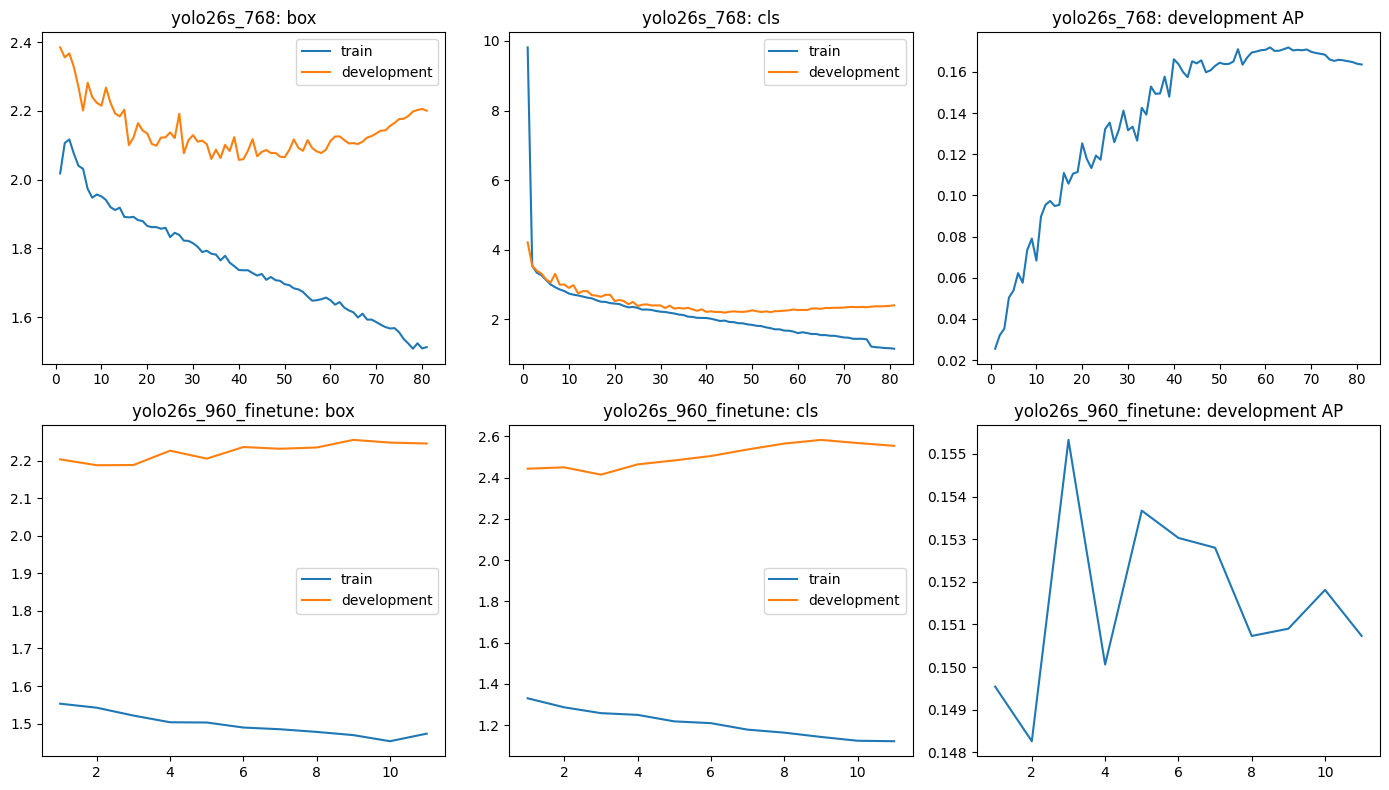

{
  "images": 500,
  "train_probe_AP50": 0.7356625365388716,
  "train_probe_AP": 0.3867454186971152,
  "warning": "Training probe is not independent; inspect both domain gaps and curves."
}


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for row, name in enumerate(CHECKPOINTS):
    history = pd.read_csv(BASE / 'histories' / (name + '.csv'))
    history.columns = history.columns.str.strip()
    for col, component in enumerate(['box', 'cls']):
        axes[row, col].plot(history.epoch, history[f'train/{component}_loss'], label='train')
        axes[row, col].plot(history.epoch, history[f'val/{component}_loss'], label='development')
        axes[row, col].set_title(name + ': ' + component)
        axes[row, col].legend()
    axes[row, 2].plot(history.epoch, history['metrics/mAP50-95(B)'])
    axes[row, 2].set_title(name + ': development AP')
    display(history.tail(5))
fig.tight_layout()
fig.savefig(OUT / 'training_curves.png', dpi=150)
plt.show()
print((BASE / 'training_gap_diagnostic.json').read_text())


## 4. Evaluate the six configurations

Evaluate both saved checkpoints at three predeclared sizes. Square padding, batch size, confidence floor, NMS IoU and maximum detections stay fixed. This isolates evaluation resolution and avoids different rectangular batch shapes across domains. Save after each evaluation so completed work survives a later error. All metrics here are development estimates.

In [4]:
assert DEVICE != 'cpu', 'Preflight passed; enable GPU for full comparison.'
print('Stage 4: starting twelve development evaluations', flush=True)
rows, class_rows = [], []
for name, checkpoint in CHECKPOINTS.items():
    for size in [640, 768, 960]:
        for domain in ['in_domain_dev', 'china_dev']:
            print('Evaluating:', name, size, domain, flush=True)
            detector = YOLO(str(checkpoint))
            metrics = detector.val(
                data=YAMLS[domain], imgsz=size, batch=4, device=DEVICE, workers=2,
                rect=False, conf=0.001, iou=0.7, max_det=300, nms=True,
                augment=False, plots=False, project=str(OUT / 'evaluations'),
                name=f'{name}_{size}_{domain}')
            rows.append(dict(candidate=name, size=size, domain=domain,
                             mAP50=float(metrics.box.map50), mAP50_95=float(metrics.box.map),
                             precision=float(metrics.box.mp), recall=float(metrics.box.mr)))
            for index, category in enumerate(metrics.box.ap_class_index):
                p, r, ap50, ap = metrics.box.class_result(index)
                class_rows.append(dict(candidate=name, size=size, domain=domain,
                    class_name=CLASSES[int(category)], precision=float(p), recall=float(r),
                    AP50=float(ap50), AP50_95=float(ap)))
            pd.DataFrame(rows).to_csv(OUT / 'domain_results.csv', index=False)
            pd.DataFrame(class_rows).to_csv(OUT / 'class_results.csv', index=False)
            del detector, metrics
            gc.collect()
            torch.cuda.empty_cache()
results = pd.DataFrame(rows)
ranking = results.groupby(['candidate', 'size']).agg(
    worst_domain_AP=('mAP50_95', 'min'), mean_domain_AP=('mAP50_95', 'mean'),
    worst_domain_AP50=('mAP50', 'min')).sort_values(
        ['worst_domain_AP', 'mean_domain_AP'], ascending=False)
ranking.to_csv(OUT / 'ranking.csv')
WINNER, SIZE = ranking.index[0]
SIZE = int(SIZE)
display(results)
display(ranking)
print('Development-selected configuration:', WINNER, SIZE)


Stage 4: starting twelve development evaluations
Evaluating: yolo26s_768 640 in_domain_dev
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1645.1±313.0 MB/s, size: 65.0 KB)
val: Scanning /kaggle/temp/roadscan_development_cache/in_domain_dev/labels... 1000 images, 358 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 1.4Kit/s 0.7s0ss
val: New cache created: /kaggle/temp/roadscan_development_cache/in_domain_dev/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 250/250 23.4it/s 10.7s0.1s
                   all       1000       1260      0.584      0.457      0.486      0.225
                   D00        250        348      0.551      0.399      0.422      0.181
                   D10        153        250      0.463       0.34      0.357      0.137


,candidate,size,domain,mAP50,mAP50_95,precision,recall
0,yolo26s_768,640,in_domain_dev,0.485967,0.224765,0.584053,0.456908
1,yolo26s_768,640,china_dev,0.244239,0.095103,0.334074,0.298092
2,yolo26s_768,768,in_domain_dev,0.507040,0.238075,0.557374,0.511857
3,yolo26s_768,768,china_dev,0.243232,0.091837,0.333847,0.316953
4,yolo26s_768,960,in_domain_dev,0.501047,0.228554,0.557463,0.505471
5,yolo26s_768,960,china_dev,0.217884,0.074597,0.313810,0.282727
6,yolo26s_960_finetune,640,in_domain_dev,0.468742,0.219550,0.578645,0.452899
7,yolo26s_960_finetune,640,china_dev,0.213571,0.083407,0.299742,0.267467
8,yolo26s_960_finetune,768,in_domain_dev,0.492508,0.232959,0.544324,0.488331
9,yolo26s_960_finetune,768,china_dev,0.212685,0.081171,0.290516,0.287278


worst_domain_AP  mean_domain_AP  worst_domain_AP50
candidate            size                                                    
yolo26s_768          640          0.095103        0.159934           0.244239
                     768          0.091837        0.164956           0.243232
yolo26s_960_finetune 640          0.083407        0.151479           0.213571
                     768          0.081171        0.157065           0.212685
yolo26s_768          960          0.074597        0.151575           0.217884
yolo26s_960_finetune 960          0.072769        0.152925           0.203503

Development-selected configuration: yolo26s_768 640


## 5. Calibrate and check visual predictions

Select a confidence threshold from the fixed mixed-development F1 curve. This threshold is for deployment and does not change the AP ranking. Predict single images to bound GPU memory. Visual examples are diagnostic, not a substitute for aggregate metrics.

In [5]:
detector = YOLO(str(CHECKPOINTS[WINNER]))
metrics = detector.val(data=YAMLS['development'], imgsz=SIZE, batch=4,
    device=DEVICE, workers=2, rect=False, conf=0.001, iou=0.7, max_det=300,
    nms=True, plots=True, project=str(OUT / 'calibration'), name='selected')
confidence = None
for title, curve in zip(metrics.curves, metrics.curves_results):
    if 'F1' in title:
        x, y = np.asarray(curve[0]), np.asarray(curve[1])
        confidence = float(x[np.argmax(y.mean(axis=0) if y.ndim == 2 else y)])
        break
assert confidence is not None
paths = (OUT / 'development.txt').read_text().splitlines()
for path in paths[:8]:
    detector.predict(path, imgsz=SIZE, conf=confidence, iou=0.7, max_det=300,
                     nms=True, rect=False, device=DEVICE, save=True, verbose=False,
                     project=str(OUT), name='examples', exist_ok=True)


Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,466,728 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1964.7±392.8 MB/s, size: 87.0 KB)
val: Scanning /kaggle/temp/roadscan_development_cache/development/labels... 1000 images, 199 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 1.3Kit/s 0.7s0s
val: New cache created: /kaggle/temp/roadscan_development_cache/development/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 250/250 19.9it/s 12.6s0.1s
                   all       1000       1743      0.493      0.396      0.373      0.158
                   D00        473        830      0.445      0.257       0.25     0.0971
                   D10        255        389      0.404      0.388      0.335      0.108
                   D20        283        374      0.628      0.594      0.598       0.29
       

## 6. Package and verify

Save the selected checkpoint and its exact inference settings. Verify CPU inference in a fresh process. Report all configurations and the unmet 92% target honestly. No test score is produced and no additional model training takes place.

In [6]:
bundle = OUT / 'model_bundle'
bundle.mkdir(exist_ok=True)
shutil.copy2(CHECKPOINTS[WINNER], bundle / 'best.pt')
config = dict(classes=CLASSES, image_size=SIZE, confidence=confidence, iou=0.7,
              max_det=300, nms=True, rect=False, candidate=WINNER,
              selection='Development only; no independent local test yet')
(bundle / 'config.json').write_text(json.dumps(config, indent=2))
(bundle / 'requirements.txt').write_text('ultralytics==8.4.177\n')
code = """import argparse, json
from pathlib import Path
from ultralytics import YOLO
parser = argparse.ArgumentParser()
parser.add_argument('--image', required=True)
args = parser.parse_args()
root = Path(__file__).resolve().parent
c = json.loads((root / 'config.json').read_text())
model = YOLO(str(root / 'best.pt'))
model.predict(args.image, imgsz=c['image_size'], conf=c['confidence'],
              iou=c['iou'], max_det=c['max_det'], nms=c['nms'], rect=c['rect'],
              device='cpu', verbose=False)
print('Fresh-process CPU inference passed')
"""
(bundle / 'predict.py').write_text(code)
check = subprocess.run([sys.executable, str(bundle / 'predict.py'), '--image', paths[0]],
                       capture_output=True, text=True, timeout=180)
(OUT / 'fresh_load.txt').write_text(check.stdout + check.stderr)
assert check.returncode == 0, check.stderr
report = '\n\n'.join([
    '# RoadScan resolution audit', '## Full development comparison', results.to_markdown(index=False),
    '## Ranking', ranking.to_markdown(),
    'Selected: ' + WINNER + ', size=' + str(SIZE),
    '92% mAP50 on both development domains: ' + str(bool(ranking.iloc[0].worst_domain_AP50 >= 0.92)),
    'Training probe performance is not an independent score. Training curves show a train/development gap; do not claim zero overfitting.',
    'Resolution was selected on development data. No new blind-test claim is made. A new annotated local evaluation is still required.',
    'No retraining was performed. Fresh-process CPU inference passed.' ])
(OUT / 'REPORT.md').write_text(report)
(bundle / 'MODEL_CARD.md').write_text(report)
(bundle / 'SHA256.json').write_text(json.dumps({p.name: hashlib.sha256(p.read_bytes()).hexdigest()
    for p in bundle.iterdir() if p.is_file()}, indent=2))
shutil.make_archive('/kaggle/working/roadscan_resolution_model', 'zip', root_dir=bundle)
print(report)


# RoadScan resolution audit

## Full development comparison

| candidate            |   size | domain        |    mAP50 |   mAP50_95 |   precision |   recall |
|:---------------------|-------:|:--------------|---------:|-----------:|------------:|---------:|
| yolo26s_768          |    640 | in_domain_dev | 0.485967 |  0.224765  |    0.584053 | 0.456908 |
| yolo26s_768          |    640 | china_dev     | 0.244239 |  0.0951034 |    0.334074 | 0.298092 |
| yolo26s_768          |    768 | in_domain_dev | 0.50704  |  0.238075  |    0.557374 | 0.511857 |
| yolo26s_768          |    768 | china_dev     | 0.243232 |  0.091837  |    0.333847 | 0.316953 |
| yolo26s_768          |    960 | in_domain_dev | 0.501047 |  0.228554  |    0.557463 | 0.505471 |
| yolo26s_768          |    960 | china_dev     | 0.217884 |  0.0745971 |    0.31381  | 0.282727 |
| yolo26s_960_finetune |    640 | in_domain_dev | 0.468742 |  0.21955   |    0.578645 | 0.452899 |
| yolo26s_960_finetune |    640 | china_dev     